# Paris Temperature Forecast — which score for rare events?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ml-arena/competition-baseline/blob/main/paris_temperature/score_options.ipynb)

[The challenge](https://ml-arena.com/viewchallenge/203) ranks agents on the
**mean CRPS**. It is a good score, but an average: a cold snap or a heat
wave is a few hours among thousands and hardly moves it. This notebook
compares the options for making rare temperatures count more.

**The answer first**

| Option | Honest forecast wins? | Looks at rare events? | Verdict |
|---|---|---|---|
| 0. Mean CRPS (today) | yes | no, they are diluted | keep as the base |
| A. CRPS on the rare hours only | **no**: exaggerating wins | yes | trap |
| B. Mean of the worst 5 % CRPS | **no**: a too-wide spread wins | indirectly | a diagnostic, not a ranking |
| C. Tail CRPS (clip to the tail, then CRPS) | yes | yes | good |
| **D. CRPS + λ × tail CRPS** | **yes** | **yes** | **recommended** |
| E. Rank measures (CMA, AUC) | cannot tell: blind to spread and bias | yes | a readable extra column |
| F. Relative to the other participants, hour by hour | **no**: over-confidence wins | no: hard hours count less | trap |
| G. Skill against the field, over the whole period | yes | as much as the score it rescales | good way to *display* D |

Sections: 1. forecasters · 2. what is a rare event · 3. the options ·
4. can it be gamed? · 5. real forecasters · 6. how much weight · 7. a score that
depends on the other participants · 8. recommendation.

Reading: Taillardat et al., *Evaluating probabilistic forecasts of extremes using CRPS
distributions* (2023), and Walz, Eberl, Gneiting, *Assessing monotone dependence: area
under the curve meets rank correlation* (2025).

In [1]:
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})
pd.options.display.float_format = "{:.3f}".format

BASE = "https://raw.githubusercontent.com/ml-arena/competition-baseline/main/paris_temperature/data/"
df = pd.concat([pd.read_csv(BASE + "weather_europe_2020_2026.csv.gz"), pd.read_csv(BASE + "weather_europe_live_2026-03-04_2026-11-04.csv.gz")],
               ignore_index=True)
df["timestamp"] = pd.to_datetime(df["timestamp"])
print(f"{df.timestamp.nunique():,} hours x {df.city_name.nunique()} cities")

59,987 hours x 45 cities


## 1. The forecasters we will score

A forecast is 50 plausible temperatures (an ensemble). We build honest
forecasters and deliberately flawed ones, so that we know what a good score
should say. Fitted on 2020–2023, spread measured on 2024, scored on every hour
from 2025-01 to 2026-11, at +6 h and +48 h (all tables average the two, like
the challenge).

| Forecaster | What it does |
|---|---|
| persistence | the last observed value, one member |
| climatology | the usual temperatures for that month and hour |
| ridge, gboost | a model on the 45 cities + its 2024 errors as spread |
| gboost sharp / wide | same centre, spread × 0.5 / × 2 |
| gboost timid | never forecasts outside the season's normal range |
| gboost alarmist | exaggerates every departure from normal by 25 % |

In [2]:
def features(df):
    temp = df.pivot(index="timestamp", columns="city_name", values="temperature")
    paris = df[df["city_name"] == "Paris"].set_index("timestamp")
    X = temp.add_prefix("t_").join((temp - temp.shift(24)).add_prefix("d24_"))
    for lag in (1, 3, 6, 12, 18, 24, 48):
        X[f"paris_lag{lag}"] = paris["temperature"].shift(lag)
    for col in ("humidity", "clouds", "wind_speed", "rain"):
        X[f"paris_{col}"] = paris[col]
    hour, day = X.index.hour, X.index.dayofyear
    X["hour_sin"], X["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    X["day_sin"], X["day_cos"] = np.sin(2 * np.pi * day / 365.25), np.cos(2 * np.pi * day / 365.25)
    return X

X = features(df)
paris = X["t_Paris"]
LEVELS = (np.arange(50) + 0.5) / 50

# The season's normal range: Paris 2020-2024, per month and hour of day.
past = paris[paris.index < "2025-01-01"]
normal = past.groupby([past.index.month, past.index.hour]).quantile(LEVELS).unstack()

F, Y, VALID, LO, MED, HI = {}, {}, {}, {}, {}, {}
for h in (6, 48):
    y = paris.shift(-h)                                  # the temperature h hours later
    ok = X.notna().all(axis=1) & y.notna()
    fit = ok & (X.index < "2024-01-01")
    cal = ok & (X.index >= "2024-01-01") & (X.index < "2025-01-01")
    test = ok & (X.index >= "2025-01-01")
    valid = X.index[test] + pd.Timedelta(hours=h)
    clim = normal.reindex(pd.MultiIndex.from_arrays([valid.month, valid.hour])).to_numpy()
    lo, med, hi = np.quantile(clim, [0.1, 0.5, 0.9], axis=1)
    Y[h], VALID[h], LO[h], MED[h], HI[h] = y[test].to_numpy(), valid, lo, med, hi

    F.setdefault("persistence", {})[h] = paris[test].to_numpy()[:, None]
    F.setdefault("climatology", {})[h] = clim
    for name, model in [("ridge", Ridge(alpha=1.0)),
                        ("gboost", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0))]:
        model.fit(X[fit], y[fit])
        errors = np.quantile(y[cal] - model.predict(X[cal]), LEVELS)
        centre = model.predict(X[test])
        F.setdefault(name, {})[h] = centre[:, None] + errors
    F.setdefault("gboost sharp", {})[h] = centre[:, None] + 0.5 * errors
    F.setdefault("gboost wide", {})[h] = centre[:, None] + 2 * errors
    F.setdefault("gboost timid", {})[h] = np.clip(centre, lo, hi)[:, None] + errors
    F.setdefault("gboost alarmist", {})[h] = (med + 1.25 * (centre - med))[:, None] + errors

print(f"{len(Y[6]):,} forecasts per lead time, {VALID[6][0]:%Y-%m-%d} → {VALID[6][-1]:%Y-%m-%d}")

16,133 forecasts per lead time, 2025-01-01 → 2026-11-04


## 2. What is a rare event?

Two definitions:

- **absolute**: below 1.4 °C or above 24.3 °C (the coldest and hottest 5 % of 2020–2024);
- **for the season**: outside the range that holds 80 % of the temperatures
  *for that month and hour of day* (the band below).

Absolute thresholds are simple, but they only ever fire in deep winter and on
summer afternoons: for months the score would not look at rare events at all.
The seasonal band gives unusual hours all year round, so that is the
definition used from here on.

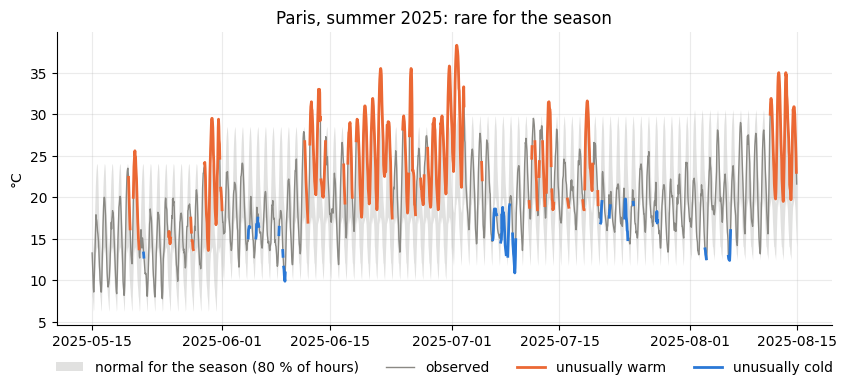

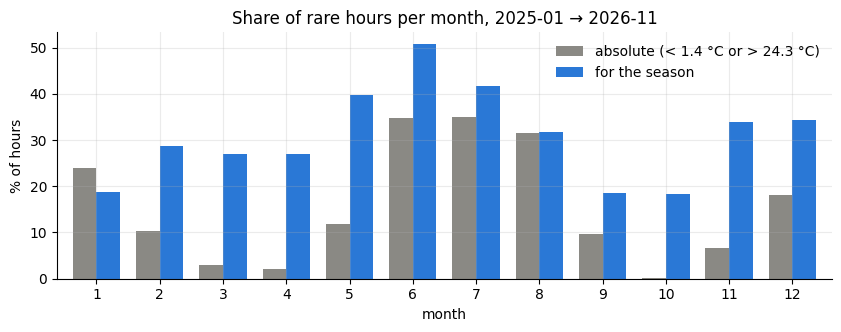

rare for the season: 31% of the scored hours (20 % by construction on 2020-2024; 2025-2026 ran warm)


In [3]:
view = (VALID[6] >= "2025-05-15") & (VALID[6] < "2025-08-15")
t, y, lo, hi = VALID[6][view], Y[6][view], LO[6][view], HI[6][view]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(t, lo, hi, color=GRAY, alpha=0.25, lw=0, label="normal for the season (80 % of hours)")
ax.plot(t, y, color=GRAY, lw=1, label="observed")
ax.plot(t, np.where(y > hi, y, np.nan), color=ORANGE, label="unusually warm")
ax.plot(t, np.where(y < lo, y, np.nan), color=BLUE, label="unusually cold")
ax.set(title="Paris, summer 2025: rare for the season", ylabel="°C")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.show()

y, month = Y[6], VALID[6].month
share = pd.DataFrame({
    "absolute (< 1.4 °C or > 24.3 °C)": pd.Series((y < 1.4) | (y > 24.3)).groupby(month).mean(),
    "for the season": pd.Series((y < LO[6]) | (y > HI[6])).groupby(month).mean(),
}) * 100
ax = share.plot.bar(color=[GRAY, BLUE], width=0.75, figsize=(10, 3.2), rot=0)
ax.set(title="Share of rare hours per month, 2025-01 → 2026-11", xlabel="month", ylabel="% of hours")
ax.legend(frameon=False)
plt.show()
print(f"rare for the season: {((y < LO[6]) | (y > HI[6])).mean():.0%} of the scored hours "
      f"(20 % by construction on 2020-2024; 2025-2026 ran warm)")

## 3. The options

### 0. Mean CRPS (today)

`CRPS = mean|xᵢ − y| − ½ mean|xᵢ − xⱼ|`, in °C, lower is better. The figure
shows the problem: forecasts are clearly worse on unusual hours, but those
hours are few, so the mean is mostly made of ordinary weather.

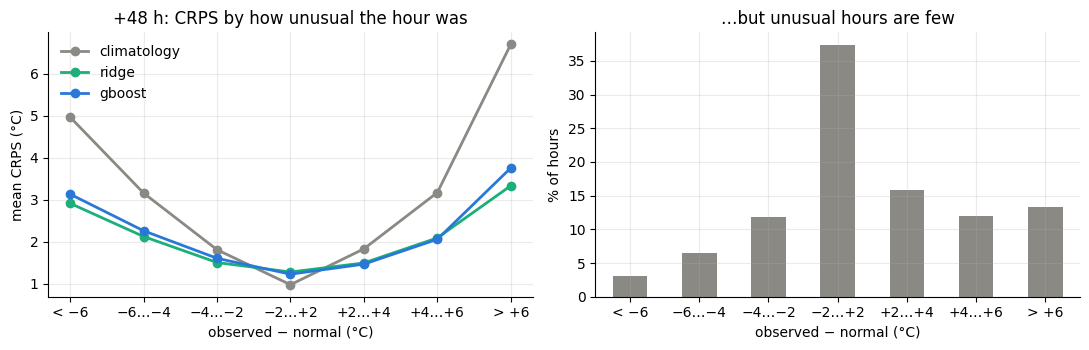

In [4]:
def crps(x, y):
    """Ensembles x (N, M) against observations y (N,): one CRPS per forecast."""
    x = np.sort(x, axis=1)
    m = x.shape[1]
    spread = (x * (2 * np.arange(m) - m + 1)).sum(axis=1) / m**2     # = ½ mean|xi − xj|
    return np.abs(x - y[:, None]).mean(axis=1) - spread

h = 48
anomaly = Y[h] - MED[h]                      # how far from normal the observation was
bins = [-np.inf, -6, -4, -2, 2, 4, 6, np.inf]
labels = ["< −6", "−6…−4", "−4…−2", "−2…+2", "+2…+4", "+4…+6", "> +6"]
group = pd.cut(anomaly, bins, labels=labels)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
for name, color in [("climatology", GRAY), ("ridge", AQUA), ("gboost", BLUE)]:
    pd.Series(crps(F[name][h], Y[h])).groupby(group, observed=True).mean().plot(ax=a, marker="o", color=color, label=name)
a.set(title="+48 h: CRPS by how unusual the hour was", xlabel="observed − normal (°C)", ylabel="mean CRPS (°C)")
a.legend(frameon=False)
(pd.Series(group).value_counts(normalize=True, sort=False) * 100).plot.bar(ax=b, color=GRAY, rot=0)
b.set(title="…but unusual hours are few", xlabel="observed − normal (°C)", ylabel="% of hours")
plt.tight_layout(); plt.show()

### A to E in a few lines each

- **A. CRPS on the rare hours only**: average the CRPS over the hours whose
  *observation* was rare. Tempting, and wrong (section 4).
- **B. Mean of the worst 5 %**: Taillardat et al. propose to look at the CRPS
  as a *distribution* instead of its mean; the simplest summary of its tail is
  the mean of the worst 5 % of forecasts.
- **C. Tail CRPS** (threshold-weighted CRPS): clip the ensemble *and* the
  observation to the rare zone, then take the ordinary CRPS. Whatever happens
  inside the normal range becomes invisible; only what the forecast says about
  the tails is scored. Every hour takes part, not only the rare ones: that is
  what keeps it honest.
- **D. CRPS + λ × tail CRPS**: the plain CRPS, where being wrong about a rare
  temperature costs (1 + λ) times more. Still in °C.
- **E. Rank measures** (Walz et al.): CMA is the AUC generalised to a
  continuous outcome: 0.5 = no information, 1 = the forecast orders the
  outcomes perfectly. The AUC itself answers "does the forecast see rare hours
  coming?". Both only look at ranks.

In [5]:
def tail_crps(x, y, lo, hi):
    """C. Clip everything to the cold tail (below lo) and the warm tail (above hi), then CRPS."""
    lo, hi = np.reshape(lo, (-1, 1)), np.reshape(hi, (-1, 1))
    cold = crps(np.minimum(x, lo), np.minimum(y, lo[:, 0]))
    warm = crps(np.maximum(x, hi), np.maximum(y, hi[:, 0]))
    return cold + warm

LAMBDA = 2
SCORES = {                                   # each: (x, y, lo, hi) -> one number, lower is better
    "0. CRPS": lambda x, y, lo, hi: crps(x, y).mean(),
    "A. rare hours only": lambda x, y, lo, hi: crps(x, y)[(y < lo) | (y > hi)].mean(),
    "B. worst 5 %": lambda x, y, lo, hi: np.sort(crps(x, y))[-len(y) // 20:].mean(),
    "C. tail CRPS": lambda x, y, lo, hi: tail_crps(x, y, lo, hi).mean(),
    "D. CRPS + 2 tail": lambda x, y, lo, hi: (crps(x, y) + LAMBDA * tail_crps(x, y, lo, hi)).mean(),
}

def cma(forecast, y):
    """E. Coefficient of monotone association: 0.5 = no information, 1 = perfect ordering."""
    rf, ry = rankdata(forecast), rankdata(y)
    centre = (len(y) + 1) / 2
    return (((rf - centre) * (ry - centre)).sum() / ((ry - centre) ** 2).sum() + 1) / 2

def auc(probability, event):
    """E. Chance that a rare hour got a higher forecast probability than an ordinary one."""
    r = rankdata(probability)
    n1 = event.sum()
    return (r[event].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(event) - n1))

## 4. Can it be gamed?

A score is **proper** when the best strategy is to say what you really
believe. To test it we need a world where the truth is known: here the
temperature is `signal + noise`, and the ideal forecast is the signal with
exactly the noise's spread. We then let a forecaster cheat in two ways,
stretching the spread or exaggerating the signal, and look at which
setting each score prefers. An honest score answers **1 and 1**.

In [6]:
rng = np.random.default_rng(0)
n = 100_000
signal = rng.normal(0, 3, n)                 # what can be known in advance
truth = signal + rng.normal(0, 1, n)         # what happens
z = np.array([NormalDist().inv_cdf(p) for p in LEVELS])
lo, hi = np.quantile(truth, [0.1, 0.9])      # rare = the lowest and highest 10 %

def forecast(spread=1.0, exaggeration=1.0):
    return (exaggeration * signal)[:, None] + spread * z

grid = [0.5, 0.75, 0.9, 1, 1.1, 1.25, 1.5, 2, 3]
best = pd.DataFrame({
    "preferred spread": {k: min(grid, key=lambda s: f(forecast(spread=s), truth, lo, hi)) for k, f in SCORES.items()},
    "preferred exaggeration": {k: min(grid, key=lambda a: f(forecast(exaggeration=a), truth, lo, hi)) for k, f in SCORES.items()},
})
best["honest forecast wins"] = (best == 1).all(axis=1).map({True: "yes", False: "NO"})
display(best)

print("E. CMA of the ensemble median, for spread 0.5 / 1 / 3 and exaggeration 0.5 / 1 / 3:")
print("  ", [round(float(cma(np.median(forecast(s, a), axis=1), truth)), 3) for s, a in [(0.5, 1), (1, 1), (3, 1), (1, 0.5), (1, 1), (1, 3)]])

,preferred spread,preferred exaggeration,honest forecast wins
0. CRPS,1.000,1.000,yes
A. rare hours only,1.100,1.100,NO
B. worst 5 %,3.000,1.000,NO
C. tail CRPS,1.000,1.000,yes
D. CRPS + 2 tail,1.000,1.000,yes


E. CMA of the ensemble median, for spread 0.5 / 1 / 3 and exaggeration 0.5 / 1 / 3:
   [0.972, 0.972, 0.972, 0.972, 0.972, 0.972]


**Reading**

- **A** rewards exaggeration: when only the rare hours count, crying wolf is
  never punished (the *forecaster's dilemma*).
- **B** rewards a too-wide spread: a vague forecast is never very wrong.
  As a *ranking* it would teach agents to be vague.
- **0, C and D** are minimised by the honest forecast.
- **E** gives the same value whatever the spread or the exaggeration: ranks
  cannot see them. It measures whether the forecast *orders* the outcomes,
  not whether its numbers are right.

## 5. On the real forecasters

Mean of +6 h and +48 h. For A–D lower is better; for the two E columns
higher is better (computed on departures from normal, otherwise the seasons
alone give 0.93 to anyone).

In [7]:
def both(f):
    """Average a per-lead-time number over +6 h and +48 h, for every forecaster."""
    return pd.Series({name: np.mean([f(F[name][h], h) for h in (6, 48)]) for name in F})

results = pd.DataFrame({k: both(lambda x, h: f(x, Y[h], LO[h], HI[h])) for k, f in SCORES.items()})
results["E. CMA"] = both(lambda x, h: cma(np.median(x, axis=1) - MED[h], Y[h] - MED[h]))
results["E. AUC rare hour"] = both(lambda x, h: auc(((x < LO[h][:, None]) | (x > HI[h][:, None])).mean(axis=1),
                                                     (Y[h] < LO[h]) | (Y[h] > HI[h])))
results.sort_values("0. CRPS")

,0. CRPS,A. rare hours only,B. worst 5 %,C. tail CRPS,D. CRPS + 2 tail,E. CMA,E. AUC rare hour
gboost,1.394,1.990,5.059,0.412,2.217,0.881,0.793
ridge,1.428,1.932,4.877,0.411,2.251,0.879,0.790
gboost alarmist,1.469,1.839,5.296,0.467,2.402,0.881,0.797
gboost sharp,1.508,2.240,5.654,0.445,2.397,0.881,0.792
gboost wide,1.573,1.983,4.251,0.497,2.567,0.881,0.771
gboost timid,1.575,2.660,6.588,0.576,2.727,0.876,0.780
climatology,2.504,4.895,9.429,0.680,3.864,0.500,0.499
persistence,3.231,3.760,9.885,1.152,5.536,0.799,0.640


Two flawed forecasters tell the options apart. **Timid** is fine on ordinary
days and wrong exactly on rare ones: a good rare-event score should punish it
*more* than the CRPS does. **Alarmist** is wrong every day: no score should
reward it.

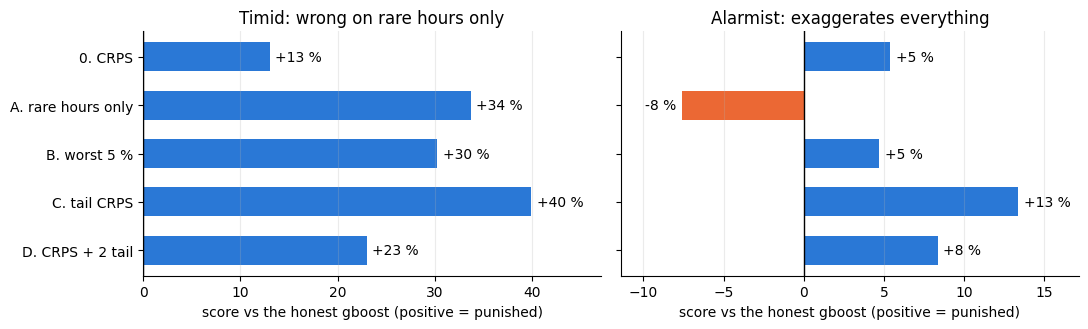

In [8]:
penalty = (results.loc[["gboost timid", "gboost alarmist"], list(SCORES)] / results.loc["gboost", list(SCORES)] - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, name, title in [(axes[0], "gboost timid", "Timid: wrong on rare hours only"),
                        (axes[1], "gboost alarmist", "Alarmist: exaggerates everything")]:
    values = penalty.loc[name][::-1]
    bars = ax.barh(values.index, values, color=[BLUE if v > 0 else ORANGE for v in values], height=0.6)
    ax.bar_label(bars, fmt="%+.0f %%", padding=4)
    ax.axvline(0, color="black", lw=1)
    ax.set(title=title, xlabel="score vs the honest gboost (positive = punished)")
    ax.margins(x=0.18); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Reading**

- The **CRPS** does see the timid forecaster, but weakly: its mistakes are
  diluted in the ordinary hours.
- **A** punishes timid the most, and *rewards* the alarmist: unusable.
- **C and D** punish timid two to three times more than the CRPS, and still
  punish the alarmist.
- **E** (table above) hardly moves between the honest, sharp, wide and
  alarmist versions: readable, but it cannot rank ensembles on its own.

One caution, which is the point of Taillardat et al.: rare events are rare.
A tail score is built on fewer informative hours, so it needs a longer
period to separate two agents. Below, how often the honest gboost beats
its over-confident copy within a single week: the tail score alone (C) is
close to a coin toss, the blend (D) keeps most of the CRPS's reliability.

In [9]:
def weekly_wins(better, worse, per_forecast):
    """% of weeks in which `better` has the lower score."""
    wins = []
    for h in (6, 48):
        gap = per_forecast(F[worse][h], h) - per_forecast(F[better][h], h)
        wins.append(pd.Series(gap, index=VALID[h]).resample("W").mean())
    gap = sum(wins)
    return (gap > 0).sum() / (gap != 0).sum() * 100        # weeks where the two differ

PER_FORECAST = {
    "0. CRPS": lambda x, h: crps(x, Y[h]),
    "C. tail CRPS": lambda x, h: tail_crps(x, Y[h], LO[h], HI[h]),
    "D. CRPS + 2 tail": lambda x, h: crps(x, Y[h]) + LAMBDA * tail_crps(x, Y[h], LO[h], HI[h]),
}
pd.DataFrame({
    "gboost beats sharp": {k: weekly_wins("gboost", "gboost sharp", f) for k, f in PER_FORECAST.items()},
}).round(0).astype(int).add_suffix(" (% of weeks)")

,gboost beats sharp (% of weeks)
0. CRPS,94
C. tail CRPS,60
D. CRPS + 2 tail,86


## 6. How much weight on rare events?

λ is a dial. With λ = 0 the score is today's CRPS; with a large λ only the
tails matter and the score gets noisy. The table shows, for the honest
gboost, how much of the score comes from the two tails, and what the timid
forecaster loses.

In [10]:
rows = {}
for lam in (0, 1, 2, 4, 9):
    total = both(lambda x, h: (crps(x, Y[h]) + lam * tail_crps(x, Y[h], LO[h], HI[h])).mean())
    tails = both(lambda x, h: ((1 + lam) * tail_crps(x, Y[h], LO[h], HI[h])).mean())
    rows[f"λ = {lam}"] = {
        "a rare miss costs": f"× {1 + lam}",
        "score of gboost (°C)": round(total["gboost"], 3),
        "share of the score from the tails": f"{tails['gboost'] / total['gboost']:.0%}",
        "timid is punished by": f"{total['gboost timid'] / total['gboost'] - 1:+.0%}",
        "ranking": " > ".join(total.sort_values().index[:4]),
    }
pd.DataFrame(rows).T

,a rare miss costs,score of gboost (°C),share of the score from the tails,timid is punished by,ranking
λ = 0,× 1,1.394,30%,+13%,gboost > ridge > gboost alarmist > gboost sharp
λ = 1,× 2,1.805,46%,+19%,gboost > ridge > gboost alarmist > gboost sharp
λ = 2,× 3,2.217,56%,+23%,gboost > ridge > gboost sharp > gboost alarmist
λ = 4,× 5,3.040,68%,+28%,gboost > ridge > gboost sharp > gboost alarmist
λ = 9,× 10,5.099,81%,+33%,gboost > ridge > gboost sharp > gboost alarmist


## 7. A score that depends on the other participants?

The idea: when most participants are close, a miss should cost more. Two
ways to do it:

- **F. Hour by hour**: divide your CRPS of each hour by the median CRPS of
  the field on that hour, then average. An error on an hour that most people
  got right costs a lot; an error everyone made costs little.
- **G. Over the whole period**: `skill = 1 − your mean score / the median
  participant's mean score`. The same ranking as the score itself, shown as
  "x % better than the field".

Same test as in section 4, with a field of 15 honest participants of
varying quality:

In [11]:
field = []                                   # 15 honest participants, each with its own error
for k in range(15):
    error = rng.uniform(0.2, 1.0)
    centre = signal + rng.normal(0, error, n)
    field.append(crps(centre[:, None] + np.sqrt(1 + error**2) * z, truth))
field_median = np.median(field, axis=0)      # the field's CRPS, hour by hour

RELATIVE = {
    "F. ratio to the field, hour by hour": lambda c: (c / field_median).mean(),
    "G. skill against the field, whole period": lambda c: c.mean() / field_median.mean(),
}
best = pd.DataFrame({
    "preferred spread": {k: min(grid, key=lambda s: f(crps(forecast(spread=s), truth))) for k, f in RELATIVE.items()},
    "preferred exaggeration": {k: min(grid, key=lambda a: f(crps(forecast(exaggeration=a), truth))) for k, f in RELATIVE.items()},
})
best["honest forecast wins"] = (best == 1).all(axis=1).map({True: "yes", False: "NO"})
display(best)

# On the real forecasters: the field is the eight of them.
def relative(name, hour_by_hour):
    out = []
    for h in (6, 48):
        all_crps = {m: crps(F[m][h], Y[h]) for m in F}
        med = np.median(list(all_crps.values()), axis=0)
        out.append((all_crps[name] / med).mean() if hour_by_hour else all_crps[name].mean() / med.mean())
    return np.mean(out)

pd.DataFrame({
    "0. CRPS (°C)": results["0. CRPS"],
    "F. ratio hour by hour": {m: relative(m, True) for m in F},
    "G. ratio whole period": {m: relative(m, False) for m in F},
}).sort_values("0. CRPS (°C)")

,preferred spread,preferred exaggeration,honest forecast wins
"F. ratio to the field, hour by hour",0.750,1,NO
"G. skill against the field, whole period",1.000,1,yes


,0. CRPS (°C),F. ratio hour by hour,G. ratio whole period
gboost,1.394,0.894,0.919
ridge,1.428,1.027,0.964
gboost alarmist,1.469,0.994,0.990
gboost sharp,1.508,0.875,0.993
gboost wide,1.573,1.207,1.038
gboost timid,1.575,1.034,1.080
climatology,2.504,2.114,1.841
persistence,3.231,3.007,2.448


**Reading**

- **F is not honest**: it prefers a spread narrower than the truth. Dividing
  by the field's error gives the most weight to the hours where the outcome
  fell where everybody expected it, and on those hours a narrow, over-confident
  ensemble scores best. It also works *against* rare events: a heat wave that
  surprises everyone becomes a cheap hour. On the real forecasters above,
  the over-confident *gboost sharp* overtakes the honest gboost.
- F has two practical costs too: a score that changes when other people
  submit, and that cannot be computed alone in a notebook.
- **G is honest**, because it is the same score divided by one number. It
  does what the idea is after: when everyone is within 0.05 °C, the
  leaderboard reads "+3 %, +1 %, −2 % against the field" instead of three
  near-identical values. Use it for display.

## 8. Recommendation

**Rank on D, `CRPS + 2 × tail CRPS`, with the seasonal band.**

```python
lo, hi = normal range of Paris for that month and hour   # fixed table, published
score  = crps(x, y) \
       + 2 * (crps(min(x, lo), min(y, lo)) + crps(max(x, hi), max(y, hi)))
```

- **Easy to read**: it is the CRPS, where a miss on an unusually cold or
  warm temperature costs 3 times more. Same unit (°C), same code plus two
  lines, one value still gives the absolute error.
- **Honest**: saying what you believe is the best strategy (section 4),
  unlike scoring the rare hours only.
- **Rare events matter all year**: more than half of the score comes from
  the tails instead of under a third, in every month.
- **The cost**: a little more week-to-week noise (section 5). Keep ranking
  on the mean over all scored runs, and keep λ moderate: λ = 2 here.

To show next to it, as columns rather than as the ranking:

- the plain **CRPS** (continuity with today's leaderboard);
- a **skill** reading, `1 − score / reference score` (0 = no better than the
  reference, 1 = perfect), for the whole score and for the tails alone, as
  below. The reference is the calendar (climatology) or, to spread out a
  leaderboard where everyone is close, the median participant (G);
- optionally the **AUC "rare hour"** of option E: "how often does the agent
  see an unusual hour coming", from 0.5 to 1.

What no average can do (Taillardat et al.): certify that a forecaster has the
right behaviour for events *more extreme than anything in the scoring
period*. For that one studies the distribution of the CRPS on a long
archive, not a leaderboard number.

In [12]:
reference = results.loc["climatology"]
skill = pd.DataFrame({
    "CRPS (°C)": results["0. CRPS"],
    "recommended score (°C)": results["D. CRPS + 2 tail"],
    "skill, all hours": 1 - results["0. CRPS"] / reference["0. CRPS"],
    "skill, rare temperatures": 1 - results["C. tail CRPS"] / reference["C. tail CRPS"],
    "AUC rare hour": results["E. AUC rare hour"],
}).sort_values("recommended score (°C)")
skill.style.format({"CRPS (°C)": "{:.3f}", "recommended score (°C)": "{:.3f}", "skill, all hours": "{:.0%}",
                    "skill, rare temperatures": "{:.0%}", "AUC rare hour": "{:.2f}"})

,CRPS (°C),recommended score (°C),"skill, all hours","skill, rare temperatures",AUC rare hour
gboost,1.394,2.217,44%,39%,0.79
ridge,1.428,2.251,43%,39%,0.79
gboost sharp,1.508,2.397,40%,35%,0.79
gboost alarmist,1.469,2.402,41%,31%,0.80
gboost wide,1.573,2.567,37%,27%,0.77
gboost timid,1.575,2.727,37%,15%,0.78
climatology,2.504,3.864,0%,0%,0.50
persistence,3.231,5.536,-29%,-69%,0.64
